# การพัฒนาระบบแนะนำเส้นทางการเรียนรู้ภาษาอังกฤษเฉพาะบุคคลโดยใช้เทคนิค Deep Q-Network (DQN)
**วัตถุประสงค์:** พัฒนาโมเดล Reinforcement Learning (DQN) เพื่อเลือกกิจกรรมการเรียนรู้ภาษาอังกฤษให้เหมาะสมกับระดับความสามารถและพัฒนาการของผู้เรียนจำลอง
**ขั้นตอนหลัก:**
1. การเตรียมไลบรารีและการตั้งค่า
2. การสร้างข้อมูลผู้เรียนจำลอง (Simulated Learners) 100,000 คน
3. การพัฒนาสภาพแวดล้อมจำลอง (Simulation Environment - MDP)
4. การพัฒนาและฝึกสอนโมเดล Deep Q-Network (DQN)
5. การเปรียบเทียบกับวิธีพื้นฐาน (Random และ Weakest-Skill-First)
6. การวิเคราะห์ทางสถิติ (Statistical Analysis)
7. การประเมินความทนทาน (Robustness Test)
8. การแสดงผลและการสรุปผลอัตโนมัติ



### 1. การเตรียมไลบรารีและการตั้งค่า (Imports & Setup)
โหลดไลบรารีที่จำเป็น และกำหนดฟังก์ชันควบคุม Random Seed เพื่อให้สามารถทำซ้ำการทดลองได้ โดยแยก Seed สำหรับการสร้างชุดข้อมูลออกจาก Seed สำหรับการฝึกโมเดลแต่ละรอบ


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
import random
from collections import deque
import scipy.stats as stats
import warnings
import os

warnings.filterwarnings('ignore')

# กำหนดอุปกรณ์และฟังก์ชันควบคุม Random Seed
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def set_seed(seed=42):
    seed = int(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    # เพิ่มความสามารถในการทำซ้ำของการคำนวณบน GPU
    if hasattr(torch.backends, "cudnn"):
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

# กำหนด Seed แยกสำหรับข้อมูลและการฝึกโมเดล
DATASET_SEED = 2026
TRAIN_SEEDS = [42, 43, 44, 45, 46]
N_TRAIN_RUNS = len(TRAIN_SEEDS)
EVALUATION_SAMPLE_SEED = 2026

set_seed(DATASET_SEED)
print(f"Libraries loaded | Device: {DEVICE}")
print(f"Dataset seed: {DATASET_SEED} | Training seeds: {TRAIN_SEEDS}")


Libraries loaded | Device: cuda
Dataset seed: 2026 | Training seeds: [42, 43, 44, 45, 46]


### 2. การสร้างข้อมูลผู้เรียนจำลอง (Simulated Learners)
สร้างข้อมูลผู้เรียนจำลอง 100,000 คน แบ่งเป็น 7 กลุ่มลักษณะ และแยกข้อมูลเป็นชุด Training, Validation และ Testing การสร้างข้อมูลใช้ `DATASET_SEED` คงที่ เพื่อให้ทุกการทดลองใช้ชุดข้อมูลเดียวกัน ขณะที่การฝึกโมเดลแต่ละรอบจะเปลี่ยน Random Seed แยกจากกัน


In [2]:
def generate_simulated_learners(n_total=100000):
    n_per_group = n_total // 7
    groups = []

    # ฟังก์ชันช่วยสร้างคะแนนจำกัดช่วง 0-100
    def gen_scores(mu, std, size):
        return np.clip(np.random.normal(mu, std, size), 0, 100)

    # 1. ทักษะการฟังต่ำ
    g1 = pd.DataFrame({
        'ability_listening': gen_scores(30, 10, n_per_group),
        'ability_reading': gen_scores(60, 15, n_per_group),
        'ability_vocabulary': gen_scores(60, 15, n_per_group),
        'ability_grammar': gen_scores(60, 15, n_per_group),
        'profile': 'Low_Listening'
    })

    # 2. ทักษะการอ่านต่ำ
    g2 = pd.DataFrame({
        'ability_listening': gen_scores(60, 15, n_per_group),
        'ability_reading': gen_scores(30, 10, n_per_group),
        'ability_vocabulary': gen_scores(60, 15, n_per_group),
        'ability_grammar': gen_scores(60, 15, n_per_group),
        'profile': 'Low_Reading'
    })

    # 3. ทักษะคำศัพท์ต่ำ
    g3 = pd.DataFrame({
        'ability_listening': gen_scores(60, 15, n_per_group),
        'ability_reading': gen_scores(60, 15, n_per_group),
        'ability_vocabulary': gen_scores(30, 10, n_per_group),
        'ability_grammar': gen_scores(60, 15, n_per_group),
        'profile': 'Low_Vocab'
    })

    # 4. ทักษะไวยากรณ์ต่ำ
    g4 = pd.DataFrame({
        'ability_listening': gen_scores(60, 15, n_per_group),
        'ability_reading': gen_scores(60, 15, n_per_group),
        'ability_vocabulary': gen_scores(60, 15, n_per_group),
        'ability_grammar': gen_scores(30, 10, n_per_group),
        'profile': 'Low_Grammar'
    })

    # 5. ปานกลางทุกด้าน
    g5 = pd.DataFrame({
        'ability_listening': gen_scores(50, 10, n_per_group),
        'ability_reading': gen_scores(50, 10, n_per_group),
        'ability_vocabulary': gen_scores(50, 10, n_per_group),
        'ability_grammar': gen_scores(50, 10, n_per_group),
        'profile': 'Mid_All'
    })

    # 6. สูงทุกด้าน
    g6 = pd.DataFrame({
        'ability_listening': gen_scores(80, 10, n_per_group),
        'ability_reading': gen_scores(80, 10, n_per_group),
        'ability_vocabulary': gen_scores(80, 10, n_per_group),
        'ability_grammar': gen_scores(80, 10, n_per_group),
        'profile': 'High_All'
    })

    # 7. ไม่สมดุล
    g7 = pd.DataFrame({
        'ability_listening': gen_scores(30, 10, n_per_group),
        'ability_reading': gen_scores(85, 10, n_per_group),
        'ability_vocabulary': gen_scores(40, 10, n_per_group),
        'ability_grammar': gen_scores(75, 10, n_per_group),
        'profile': 'Unbalanced'
    })

    df = pd.concat([g1, g2, g3, g4, g5, g6, g7], ignore_index=True)
    df = df.sample(frac=1, random_state=42).reset_index(drop=True) # Shuffle

    # เพิ่มแอตทริบิวต์อื่นๆ
    df['learner_id'] = np.arange(1, len(df) + 1)
    df['learning_goal'] = 85.0 # เป้าหมายคะแนนเฉลี่ย
    df['learning_history'] = 0
    df['total_learning_time'] = 0
    df['learning_progress'] = 0
    df['initial_ability'] = df[['ability_listening', 'ability_reading', 'ability_vocabulary', 'ability_grammar']].mean(axis=1)

    # กำหนดเวลาเริ่มต้นให้ผู้เรียนแต่ละคน (นาที)
    df['time_budget'] = np.random.randint(120, 300, size=len(df))

    # แบ่ง Train (70%), Val (10%), Test (20%)
    train_split = int(0.7 * len(df))
    val_split = int(0.8 * len(df))

    df['dataset_split'] = 'Train'
    df.loc[train_split:val_split, 'dataset_split'] = 'Validation'
    df.loc[val_split:, 'dataset_split'] = 'Test'

    return df

# ใช้ Seed คงที่สำหรับสร้างชุดข้อมูล เพื่อให้ทุก Training Run ใช้ข้อมูลชุดเดียวกัน
set_seed(DATASET_SEED)
learners_df = generate_simulated_learners(100000)
learners_df.to_csv('simulated_learners.csv', index=False)
print(f"Generated {len(learners_df)} learners. Saved to simulated_learners.csv")
display(learners_df.head())



Generated 99995 learners. Saved to simulated_learners.csv


,ability_listening,ability_reading,ability_vocabulary,ability_grammar,profile,learner_id,learning_goal,learning_history,total_learning_time,learning_progress,initial_ability,time_budget,dataset_split
0,58.010865,50.742372,24.735538,51.087925,Low_Vocab,1,85.0,0,0,0,46.144175,229,Train
1,42.955497,46.770502,30.739041,79.522567,Low_Vocab,2,85.0,0,0,0,49.996902,262,Train
2,49.268530,47.537480,68.681719,38.851658,Low_Grammar,3,85.0,0,0,0,51.084847,257,Train
3,37.064249,46.977876,57.658932,38.554036,Low_Listening,4,85.0,0,0,0,45.063773,252,Train
4,25.659136,71.284165,68.012948,40.239115,Low_Listening,5,85.0,0,0,0,51.298841,194,Train


### 3. การพัฒนาสภาพแวดล้อมจำลอง (Simulation Environment)
ใช้หลักการ Markov Decision Process (MDP) กำหนด State, Action (4 ทักษะ) และ Reward (Progress - Time Cost) โดยกำหนดจำนวนขั้นตอนสูงสุดต่อ Episode เท่ากับ 50 ขั้นตอน


In [3]:
class EnglishLearningEnv:
    def __init__(self, df, max_steps=50, noise_std=2.0, learning_rate_multiplier=1.0):
        self.df = df.set_index('learner_id')
        self.max_steps = max_steps
        self.noise_std = noise_std
        self.lr_multiplier = learning_rate_multiplier

        # ต้นทุนเวลาของแต่ละกิจกรรม (นาที)
        self.time_costs = {
            0: 15.0, # Listening
            1: 20.0, # Reading
            2: 10.0, # Vocabulary
            3: 15.0  # Grammar
        }

    def reset(self, learner_id):
        self.learner_id = learner_id
        learner = self.df.loc[learner_id]

        self.abilities = np.array([
            learner['ability_listening'],
            learner['ability_reading'],
            learner['ability_vocabulary'],
            learner['ability_grammar']
        ], dtype=np.float32)

        self.initial_avg = np.mean(self.abilities)
        self.goal = learner['learning_goal']
        self.rem_time = float(learner['time_budget'])
        self.max_time = self.rem_time

        self.action_counts = np.zeros(4, dtype=np.float32)
        self.step_count = 0

        return self._get_state()

    def _get_state(self):
        # Normalize state เป็นช่วง [0, 1] สำหรับ Neural Network
        progress = np.mean(self.abilities) - self.initial_avg
        norm_abilities = self.abilities / 100.0
        norm_progress = progress / 100.0
        norm_rem_time = max(0, self.rem_time / self.max_time) if self.max_time > 0 else 0
        norm_goal = self.goal / 100.0
        norm_counts = self.action_counts / self.max_steps

        state = np.concatenate([
            norm_abilities,
            [norm_progress, norm_rem_time, norm_goal],
            norm_counts
        ])
        return state

    def step(self, action):
        time_cost = self.time_costs[action]
        self.rem_time -= time_cost
        self.action_counts[action] += 1
        self.step_count += 1

        old_avg = np.mean(self.abilities)

        # การเพิ่มคะแนน (Diminishing Returns)
        # คะแนนยิ่งใกล้ 100 ยิ่งเพิ่มยาก
        base_gain = 5.0 * self.lr_multiplier
        diminishing_factor = (100.0 - self.abilities[action]) / 100.0
        noise = np.random.normal(0, self.noise_std)
        gain = (base_gain * diminishing_factor) + noise

        # Update ability
        self.abilities[action] = np.clip(self.abilities[action] + gain, 0, 100)

        new_avg = np.mean(self.abilities)
        learning_progress_gain = new_avg - old_avg

        # Reward Function: สะท้อนความก้าวหน้าลบด้วยต้นทุนเวลา
        # ปรับ weight ให้สมดุล
        reward = (learning_progress_gain * 5.0) - (time_cost * 0.05)

        # โบนัสเมื่อถึงเป้าหมาย
        if new_avg >= self.goal and old_avg < self.goal:
            reward += 20.0

        done = bool(self.rem_time <= 0 or self.step_count >= self.max_steps or new_avg >= self.goal)

        info = {
            'abilities': self.abilities.copy(),
            'time_used': self.max_time - self.rem_time,
            'avg_ability': new_avg,
            'goal_achieved': new_avg >= self.goal
        }

        return self._get_state(), reward, done, info



### 4. การพัฒนาโมเดล Deep Q-Network (DQN)
สร้างโครงข่ายประสาทเทียมแบบ Fully Connected จำนวน 2 Hidden Layers ชั้นละ 128 neurons พร้อม Experience Replay Buffer และ Target Network โดยฝึกโมเดลซ้ำ 5 รอบด้วย Training Seeds ที่แตกต่างกัน ได้แก่ 42, 43, 44, 45 และ 46


In [4]:
class ReplayBuffer:
    def __init__(self, capacity):
        self.buffer = deque(maxlen=capacity)

    def push(self, state, action, reward, next_state, done):
        self.buffer.append((state, action, reward, next_state, done))

    def sample(self, batch_size):
        states, actions, rewards, next_states, dones = zip(
            *random.sample(self.buffer, batch_size)
        )
        return (
            np.asarray(states, dtype=np.float32),
            np.asarray(actions, dtype=np.int64),
            np.asarray(rewards, dtype=np.float32),
            np.asarray(next_states, dtype=np.float32),
            np.asarray(dones, dtype=np.float32)
        )

    def __len__(self):
        return len(self.buffer)


class DQN(nn.Module):
    def __init__(self, state_dim, action_dim):
        super(DQN, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 128),
            nn.ReLU(),
            nn.Linear(128, action_dim)
        )

    def forward(self, x):
        return self.net(x)


def train_dqn(env, train_ids, episodes=2000, seed=42):
    # ตั้ง Seed ใหม่ทุกครั้ง เพื่อให้แต่ละรอบการฝึกทำซ้ำได้
    set_seed(seed)

    state_dim = len(env.reset(int(train_ids[0])))
    action_dim = 4

    policy_net = DQN(state_dim, action_dim).to(DEVICE)
    target_net = DQN(state_dim, action_dim).to(DEVICE)
    target_net.load_state_dict(policy_net.state_dict())
    target_net.eval()

    optimizer = optim.Adam(policy_net.parameters(), lr=1e-3)
    criterion = nn.SmoothL1Loss()  # Huber Loss
    buffer = ReplayBuffer(10000)

    batch_size = 64
    gamma = 0.99
    epsilon_start = 1.0
    epsilon_end = 0.05
    epsilon_decay = 500
    target_update = 10

    history = {
        'training_seed': [],
        'episode': [],
        'reward': [],
        'epsilon': [],
        'avg_ability_gain': []
    }

    for ep in range(episodes):
        learner_id = int(random.choice(train_ids))
        state = env.reset(learner_id)
        total_reward = 0.0
        done = False
        info = None

        epsilon = epsilon_end + (epsilon_start - epsilon_end) * np.exp(
            -1.0 * ep / epsilon_decay
        )

        while not done:
            if random.random() > epsilon:
                with torch.no_grad():
                    state_t = torch.as_tensor(
                        state, dtype=torch.float32, device=DEVICE
                    ).unsqueeze(0)
                    q_values = policy_net(state_t)
                    action = int(q_values.argmax(dim=1).item())
            else:
                action = random.randrange(action_dim)

            next_state, reward, done, info = env.step(action)
            buffer.push(state, action, reward, next_state, done)
            state = next_state
            total_reward += float(reward)

            if len(buffer) >= batch_size:
                s, a, r, ns, d = buffer.sample(batch_size)

                s = torch.as_tensor(s, dtype=torch.float32, device=DEVICE)
                a = torch.as_tensor(a, dtype=torch.long, device=DEVICE).unsqueeze(1)
                r = torch.as_tensor(r, dtype=torch.float32, device=DEVICE).unsqueeze(1)
                ns = torch.as_tensor(ns, dtype=torch.float32, device=DEVICE)
                d = torch.as_tensor(d, dtype=torch.float32, device=DEVICE).unsqueeze(1)

                q_values = policy_net(s).gather(1, a)

                with torch.no_grad():
                    max_next_q = target_net(ns).max(dim=1, keepdim=True)[0]
                    target_q = r + (gamma * max_next_q * (1.0 - d))

                loss = criterion(q_values, target_q)
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

        # Hard Update: คัดลอกน้ำหนัก Online Network ไปยัง Target Network
        # เมื่อสิ้นสุดครบทุก 10 Episodes (ไม่อัปเดตหลัง Episode แรก)
        if (ep + 1) % target_update == 0:
            target_net.load_state_dict(policy_net.state_dict())

        initial_avg = env.initial_avg
        final_avg = info['avg_ability']

        history['training_seed'].append(seed)
        history['episode'].append(ep + 1)
        history['reward'].append(total_reward)
        history['epsilon'].append(float(epsilon))
        history['avg_ability_gain'].append(float(final_avg - initial_avg))

        if (ep + 1) % 500 == 0:
            recent_reward = np.mean(history['reward'][-100:])
            print(
                f"Seed {seed} | Episode {ep+1}/{episodes} | "
                f"Avg Reward (100 ep): {recent_reward:.2f} | "
                f"Epsilon: {epsilon:.3f}"
            )

    return policy_net, pd.DataFrame(history)


# ฝึกโมเดลแยกตาม Random Seed จำนวน 5 รอบ
train_ids = learners_df.loc[
    learners_df['dataset_split'] == 'Train', 'learner_id'
].to_numpy()

training_env = EnglishLearningEnv(learners_df)
dqn_models = {}
training_histories = []

print("Starting repeated DQN training...")
for run_number, run_seed in enumerate(TRAIN_SEEDS, start=1):
    print(f"\nTraining run {run_number}/{N_TRAIN_RUNS} (seed={run_seed})")
    model, run_history = train_dqn(
        training_env,
        train_ids,
        episodes=2000,
        seed=run_seed
    )
    dqn_models[run_seed] = model
    training_histories.append(run_history)
    torch.save(model.state_dict(), f"dqn_model_seed_{run_seed}.pth")

train_history = pd.concat(training_histories, ignore_index=True)
train_history.to_csv('training_history_all_seeds.csv', index=False)

# ใช้โมเดลจาก Seed สุดท้ายเป็นตัวแปรอ้างอิงสำหรับการเรียกใช้งานทั่วไป
# การประเมินผลหลักด้านล่างจะประเมินโมเดลของทุก Seed แยกจากกัน
dqn_model = dqn_models[TRAIN_SEEDS[-1]]

print("\nRepeated training completed.")
print(f"Saved {len(dqn_models)} trained models and combined training history.")
display(
    train_history.groupby('training_seed')['reward']
    .agg(['mean', 'std', 'min', 'max'])
    .rename(columns={'mean': 'Mean Reward', 'std': 'SD Reward',
                     'min': 'Min Reward', 'max': 'Max Reward'})
)


Starting repeated DQN training...

Training run 1/5 (seed=42)
Seed 42 | Episode 500/2000 | Avg Reward (100 ep): 29.78 | Epsilon: 0.400
Seed 42 | Episode 1000/2000 | Avg Reward (100 ep): 37.57 | Epsilon: 0.179
Seed 42 | Episode 1500/2000 | Avg Reward (100 ep): 34.91 | Epsilon: 0.097
Seed 42 | Episode 2000/2000 | Avg Reward (100 ep): 35.74 | Epsilon: 0.067

Training run 2/5 (seed=43)
Seed 43 | Episode 500/2000 | Avg Reward (100 ep): 34.31 | Epsilon: 0.400
Seed 43 | Episode 1000/2000 | Avg Reward (100 ep): 34.87 | Epsilon: 0.179
Seed 43 | Episode 1500/2000 | Avg Reward (100 ep): 35.53 | Epsilon: 0.097
Seed 43 | Episode 2000/2000 | Avg Reward (100 ep): 39.36 | Epsilon: 0.067

Training run 3/5 (seed=44)
Seed 44 | Episode 500/2000 | Avg Reward (100 ep): 33.29 | Epsilon: 0.400
Seed 44 | Episode 1000/2000 | Avg Reward (100 ep): 38.24 | Epsilon: 0.179
Seed 44 | Episode 1500/2000 | Avg Reward (100 ep): 35.52 | Epsilon: 0.097
Seed 44 | Episode 2000/2000 | Avg Reward (100 ep): 38.91 | Epsilon: 0.0

,Mean Reward,SD Reward,Min Reward,Max Reward
training_seed,,,,
42,34.402024,16.022603,-12.115841,97.827621
43,34.619240,16.191955,-10.516006,92.057022
44,34.761311,16.272706,-12.799004,94.660706
45,35.284963,16.308589,-14.706879,83.691750
46,35.520765,15.999811,-13.735237,90.337982


### 5. การเปรียบเทียบกับวิธีพื้นฐาน (Baseline Evaluation)
ประเมินโมเดล DQN ที่ฝึกจากแต่ละ Random Seed เปรียบเทียบกับ Random Recommendation และ Weakest-Skill-First บนกลุ่มผู้เรียนชุด Testing เดียวกัน โดยกำหนด Epsilon เท่ากับ 0 สำหรับ DQN เพื่อประเมินนโยบายที่เรียนรู้แล้วโดยไม่สุ่มสำรวจ


In [5]:
def evaluate_agent(env, learner_id, agent_type, model=None, epsilon=0.0):
    # การประเมิน DQN กำหนด epsilon=0 เพื่อเลือก action จากค่า Q-value สูงสุด
    state = env.reset(int(learner_id))
    done = False
    total_reward = 0.0
    actions_taken = []
    info = None

    while not done:
        if agent_type == 'Random':
            action = random.randrange(4)

        elif agent_type == 'Weakest-Skill':
            action = int(np.argmin(env.abilities))

        elif agent_type == 'DQN':
            if model is None:
                raise ValueError("ต้องระบุ model สำหรับการประเมิน DQN")

            if epsilon > 0.0 and random.random() < epsilon:
                action = random.randrange(4)
            else:
                with torch.no_grad():
                    state_t = torch.as_tensor(
                        state, dtype=torch.float32, device=DEVICE
                    ).unsqueeze(0)
                    q_values = model(state_t)
                    action = int(q_values.argmax(dim=1).item())
        else:
            raise ValueError(f"Unknown agent_type: {agent_type}")

        next_state, reward, done, info = env.step(action)
        state = next_state
        total_reward += float(reward)
        actions_taken.append(action)

    ability_gain = info['avg_ability'] - env.initial_avg

    return {
        'learner_id': int(learner_id),
        'agent': agent_type,
        'episode_return': total_reward,
        'ability_gain': ability_gain,
        'time_cost': info['time_used'],
        'goal_achieved': int(info['goal_achieved']),
        'num_actions': len(actions_taken)
    }


test_ids = learners_df.loc[
    learners_df['dataset_split'] == 'Test', 'learner_id'
].to_numpy()

# สุ่ม Test Set เพียงครั้งเดียวและใช้ร่วมกันทุก Training Seed
set_seed(EVALUATION_SAMPLE_SEED)
test_sample = np.random.choice(test_ids, 1000, replace=False)

eval_results = []
print("Evaluating all trained models on the same 1,000 test learners...")

for run_seed in TRAIN_SEEDS:
    model = dqn_models[run_seed]
    model.eval()

    for i, learner_id in enumerate(test_sample):
        if run_seed == TRAIN_SEEDS[0] and i % 200 == 0:
            print(f"Evaluated {i}/{len(test_sample)} learners...")

        # ใช้ Evaluation Seed เดียวกันภายในผู้เรียนและรอบการฝึกเดียวกัน
        # เพื่อควบคุมการสุ่มของ baseline และ noise ใน Environment
        eval_seed = 100000 + run_seed * 1000 + int(learner_id)

        for agent_name in ['Random', 'Weakest-Skill', 'DQN']:
            set_seed(eval_seed)
            eval_env = EnglishLearningEnv(learners_df)
            if agent_name == 'DQN':
                result = evaluate_agent(
                    eval_env, learner_id, 'DQN', model=model, epsilon=0.0
                )
            else:
                result = evaluate_agent(eval_env, learner_id, agent_name)

            result['training_seed'] = run_seed
            eval_results.append(result)

eval_df = pd.DataFrame(eval_results)
eval_df.to_csv('evaluation_results_all_seeds.csv', index=False)

print("Evaluation complete.")
print("DQN evaluation uses epsilon=0.0 (greedy policy).")
display(
    eval_df.groupby('agent')[
        ['episode_return', 'ability_gain', 'time_cost', 'goal_achieved']
    ].agg(['mean', 'std'])
)


Evaluating all trained models on the same 1,000 test learners...
Evaluated 0/1000 learners...
Evaluated 200/1000 learners...
Evaluated 400/1000 learners...
Evaluated 600/1000 learners...
Evaluated 800/1000 learners...
Evaluation complete.
DQN evaluation uses epsilon=0.0 (greedy policy).


episode_return            ability_gain           time_cost  \
                        mean        std         mean       std      mean   
agent                                                                      
DQN                38.425777  16.432967     9.588726  3.836644   208.197   
Random             25.859071  14.485628     7.173954  3.280884   211.334   
Weakest-Skill      36.430431  15.832697     9.201385  3.699099   209.610   

                         goal_achieved            
                     std          mean       std  
agent                                             
DQN            62.742263        0.0654  0.247255  
Random         61.385862        0.0484  0.214631  
Weakest-Skill  62.443877        0.0660  0.248307

### 6. การวิเคราะห์ทางสถิติ (Statistical Analysis)
วิเคราะห์ผลการประเมินแบบจับคู่ (Paired Comparison) โดยเปรียบเทียบทั้งสามวิธีบนผู้เรียนรายเดียวกันและ Training Seed เดียวกัน ใช้ Friedman Test สำหรับเปรียบเทียบ 3 วิธี และ Wilcoxon Signed-Rank Test สำหรับการเปรียบเทียบรายคู่ ทั้งนี้ให้รายงานค่าเฉลี่ยและส่วนเบี่ยงเบนมาตรฐานระหว่างรอบการฝึกประกอบผลการวิเคราะห์


In [6]:
# จัดรูปแบบข้อมูลสำหรับการทดสอบแบบ Paired
# ใช้ทั้ง training_seed และ learner_id เป็นดัชนี เพื่อรักษาการจับคู่ของผลการทดลอง
pivot_return = eval_df.pivot(
    index=['training_seed', 'learner_id'],
    columns='agent',
    values='episode_return'
).dropna()

pivot_gain = eval_df.pivot(
    index=['training_seed', 'learner_id'],
    columns='agent',
    values='ability_gain'
).dropna()

stat_results = []

def perform_stats(data_pivot, metric_name):
    dqn = data_pivot['DQN']
    rnd = data_pivot['Random']
    wst = data_pivot['Weakest-Skill']

    # Friedman Test สำหรับเปรียบเทียบ 3 วิธี
    stat, p_friedman = stats.friedmanchisquare(dqn, rnd, wst)

    # Wilcoxon Signed-Rank Test สำหรับการเปรียบเทียบรายคู่
    _, p_dqn_rnd = stats.wilcoxon(dqn, rnd)
    _, p_dqn_wst = stats.wilcoxon(dqn, wst)

    # Cohen's d แบบ pooled standard deviation สำหรับข้อมูลสองกลุ่ม
    def cohens_d(x, y):
        return (
            (np.mean(x) - np.mean(y)) /
            np.sqrt((np.var(x, ddof=1) + np.var(y, ddof=1)) / 2.0)
        )

    return {
        'Metric': metric_name,
        'Friedman_p': p_friedman,
        'Wilcoxon_DQN_vs_Random_p': p_dqn_rnd,
        'Wilcoxon_DQN_vs_Weakest_p': p_dqn_wst,
        'Cohens_D_DQN_vs_Random': cohens_d(dqn, rnd),
        'Cohens_D_DQN_vs_Weakest': cohens_d(dqn, wst)
    }


stat_results.append(perform_stats(pivot_return, 'Episode Return'))
stat_results.append(perform_stats(pivot_gain, 'Ability Gain'))

stat_df = pd.DataFrame(stat_results)
stat_df.to_csv('statistical_results_all_seeds.csv', index=False)

# สรุปผลแยกตาม Training Seed เพื่อพิจารณาความสม่ำเสมอ
seed_summary = (
    eval_df.groupby(['training_seed', 'agent'])[
        ['episode_return', 'ability_gain', 'time_cost', 'goal_achieved']
    ].mean().reset_index()
)
seed_summary.to_csv('evaluation_summary_by_seed.csv', index=False)

print("Statistical analysis complete.")
display(stat_df)
display(seed_summary)


Statistical analysis complete.


,Metric,Friedman_p,Wilcoxon_DQN_vs_Random_p,Wilcoxon_DQN_vs_Weakest_p,Cohens_D_DQN_vs_Random,Cohens_D_DQN_vs_Weakest
0,Episode Return,0.0,0.0,6.492478e-173,0.811282,0.123661
1,Ability Gain,0.0,0.0,8.337831e-154,0.676483,0.102783


,training_seed,agent,episode_return,ability_gain,time_cost,goal_achieved
0,42,DQN,38.601449,9.601890,207.360,0.068
1,42,Random,25.595677,7.131635,211.650,0.046
2,42,Weakest-Skill,36.370988,9.175398,209.320,0.068
3,43,DQN,37.642433,9.413437,207.295,0.067
4,43,Random,25.659324,7.121315,211.345,0.051
5,43,Weakest-Skill,36.161502,9.153200,210.090,0.065
6,44,DQN,39.050742,9.724998,209.085,0.065
7,44,Random,25.946482,7.208247,211.495,0.045
8,44,Weakest-Skill,36.478501,9.217601,209.390,0.064
9,45,DQN,38.267108,9.561422,208.800,0.067


### 7. การประเมินความทนทาน (Robustness Test)
ทดสอบโมเดลที่ผ่านการฝึกจากแต่ละ Random Seed ภายใต้สภาพแวดล้อมที่มีเงื่อนไขแตกต่างกัน ได้แก่ สถานการณ์ปกติ สถานการณ์ที่อัตราการเรียนรู้ลดลง และสถานการณ์ที่มีสัญญาณรบกวนสูง โดยใช้กลุ่มผู้เรียนทดสอบชุดเดียวกันในทุกวิธี


In [7]:
robustness_results = []

scenarios = {
    'Normal': {'noise_std': 2.0, 'lr_mult': 1.0},
    'Low Learning Rate': {'noise_std': 2.0, 'lr_mult': 0.5},
    'High Random Noise': {'noise_std': 5.0, 'lr_mult': 1.0},
}

# สุ่มกลุ่มผู้เรียนสำหรับ Robustness Test เพียงครั้งเดียว
set_seed(EVALUATION_SAMPLE_SEED + 1)
rob_sample = np.random.choice(test_ids, 300, replace=False)

print("Starting repeated Robustness Test...")

for run_seed in TRAIN_SEEDS:
    model = dqn_models[run_seed]
    model.eval()

    for scenario_index, (scenario_name, params) in enumerate(scenarios.items()):
        for learner_id in rob_sample:
            # ใช้ offset คงที่ตามลำดับ Scenario เพื่อให้ทำซ้ำได้ทุกครั้ง
            eval_seed = (
                200000 + run_seed * 1000
                + int(learner_id) + scenario_index * 10000
            )

            for agent_name in ['Random', 'Weakest-Skill', 'DQN']:
                set_seed(eval_seed)
                robust_env = EnglishLearningEnv(
                    learners_df,
                    noise_std=params['noise_std'],
                    learning_rate_multiplier=params['lr_mult']
                )

                if agent_name == 'DQN':
                    result = evaluate_agent(
                        robust_env, learner_id, 'DQN',
                        model=model, epsilon=0.0
                    )
                else:
                    result = evaluate_agent(
                        robust_env, learner_id, agent_name
                    )

                result['training_seed'] = run_seed
                result['scenario'] = scenario_name
                robustness_results.append(result)

rob_df = pd.DataFrame(robustness_results)
rob_df.to_csv('robustness_results_all_seeds.csv', index=False)

rob_summary = (
    rob_df.groupby(['scenario', 'training_seed', 'agent'])['episode_return']
    .mean().reset_index()
)
rob_summary.to_csv('robustness_summary_by_seed.csv', index=False)

print("Robustness Test complete.")
display(
    rob_df.groupby(['scenario', 'agent'])[
        ['episode_return', 'ability_gain', 'time_cost', 'goal_achieved']
    ].agg(['mean', 'std'])
)


Starting repeated Robustness Test...
Robustness Test complete.


episode_return            ability_gain  \
                                          mean        std         mean   
scenario          agent                                                  
High Random Noise DQN                40.644114  25.451290    10.003356   
                  Random             27.111653  24.985035     7.373631   
                  Weakest-Skill      39.233859  24.960981     9.732072   
Low Learning Rate DQN                17.088247  12.018542     5.426616   
                  Random              8.859592  10.777045     3.826652   
                  Weakest-Skill      15.906187  11.555937     5.211338   
Normal            DQN                38.672054  16.860216     9.698477   
                  Random             26.348069  14.702970     7.282381   
                  Weakest-Skill      37.021815  16.395765     9.375629   

                                            time_cost             \
                                      std        mean        std   
scenario          agent                                            
High Random Noise DQN            5.457400  206.920000  67.308002   
                  Random         5.212943  209.796667  66.684630   
                  Weakest-Skill  5.352462  208.263333  66.737070   
Low Learning Rate DQN            2.710757  209.696667  65.472506   
                  Random         2.359024  212.140000  65.128961   
                  Weakest-Skill  2.615847  210.743333  65.114187   
Normal            DQN            3.918934  208.673333  66.104361   
                  Random         3.379311  211.143333  65.459398   
                  Weakest-Skill  3.818113  209.926667  65.477117   

                                goal_achieved            
                                         mean       std  
scenario          agent                                  
High Random Noise DQN                0.076667  0.266151  
                  Random             0.064667  0.246019  
                  Weakest-Skill      0.077333  0.267209  
Low Learning Rate DQN                0.050667  0.219389  
                  Random             0.045333  0.208104  
                  Weakest-Skill      0.048000  0.213838  
Normal            DQN                0.060667  0.238797  
                  Random             0.054667  0.227404  
                  Weakest-Skill      0.062000  0.241236

### 8. การแสดงผลด้วยกราฟและการสรุปผลอัตโนมัติ (Visualization & Conclusion)
แสดงแนวโน้มการฝึกโดยใช้ค่าเฉลี่ยของผลตอบแทนในแต่ละ Episode จากทุก Training Seed และสรุปผลการประเมินโดยแสดงค่าเฉลี่ยและส่วนเบี่ยงเบนมาตรฐาน เพื่อสะท้อนความสม่ำเสมอของผลลัพธ์จากการฝึกซ้ำ


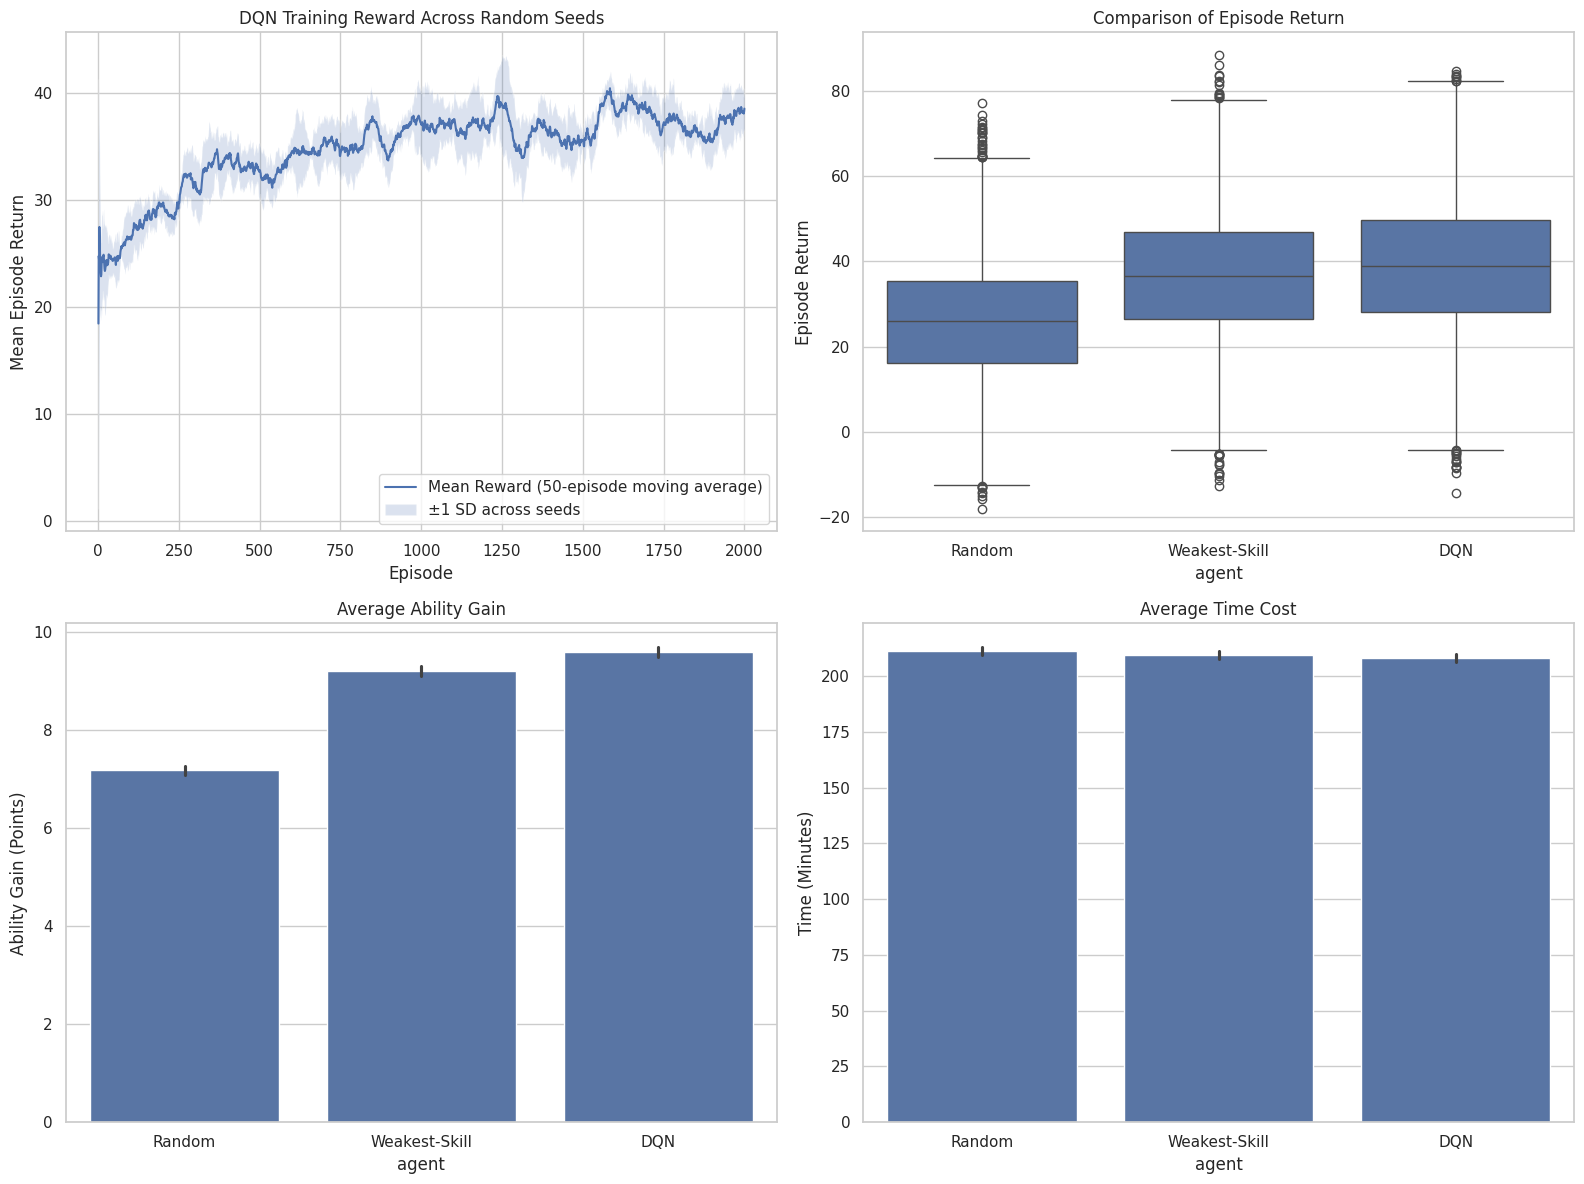

ผลการประเมินรวมทุก Training Seed (Mean ± SD)

DQN
- episode_return: 38.4258 ± 16.4330
- ability_gain: 9.5887 ± 3.8366
- time_cost: 208.1970 ± 62.7423
- goal_achieved: 0.0654 ± 0.2473

Random
- episode_return: 25.8591 ± 14.4856
- ability_gain: 7.1740 ± 3.2809
- time_cost: 211.3340 ± 61.3859
- goal_achieved: 0.0484 ± 0.2146

Weakest-Skill
- episode_return: 36.4304 ± 15.8327
- ability_gain: 9.2014 ± 3.6991
- time_cost: 209.6100 ± 62.4439
- goal_achieved: 0.0660 ± 0.2483

Friedman Test: พบความแตกต่างอย่างมีนัยสำคัญทางสถิติ (p-value = 0.0000e+00)

หมายเหตุ: ผลการประเมินรวมประกอบด้วยผลจากโมเดลที่ฝึกด้วย Training Seeds [42, 43, 44, 45, 46] จำนวน 5 รอบ


In [8]:
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Training Curve: ค่าเฉลี่ยของ Moving Average จากทุก Seed
training_plot = train_history.copy()
training_plot['rolling_reward'] = (
    training_plot.groupby('training_seed')['reward']
    .transform(lambda x: x.rolling(50, min_periods=1).mean())
)
mean_training_curve = (
    training_plot.groupby('episode')['rolling_reward']
    .agg(['mean', 'std']).reset_index()
)
axes[0, 0].plot(
    mean_training_curve['episode'],
    mean_training_curve['mean'],
    label='Mean Reward (50-episode moving average)'
)
axes[0, 0].fill_between(
    mean_training_curve['episode'],
    mean_training_curve['mean'] - mean_training_curve['std'],
    mean_training_curve['mean'] + mean_training_curve['std'],
    alpha=0.2,
    label='±1 SD across seeds'
)
axes[0, 0].set_title('DQN Training Reward Across Random Seeds')
axes[0, 0].set_xlabel('Episode')
axes[0, 0].set_ylabel('Mean Episode Return')
axes[0, 0].legend()

# 2. Episode Return
sns.boxplot(data=eval_df, x='agent', y='episode_return', ax=axes[0, 1])
axes[0, 1].set_title('Comparison of Episode Return')
axes[0, 1].set_ylabel('Episode Return')

# 3. Ability Gain
sns.barplot(data=eval_df, x='agent', y='ability_gain', ax=axes[1, 0])
axes[1, 0].set_title('Average Ability Gain')
axes[1, 0].set_ylabel('Ability Gain (Points)')

# 4. Time Cost
sns.barplot(data=eval_df, x='agent', y='time_cost', ax=axes[1, 1])
axes[1, 1].set_title('Average Time Cost')
axes[1, 1].set_ylabel('Time (Minutes)')

plt.tight_layout()
plt.savefig('results_visualization_all_seeds.png', dpi=300)
plt.show()

# สรุปผลการประเมินรวมทุก Training Seed
mean_metrics = eval_df.groupby('agent').mean(numeric_only=True)
std_metrics = eval_df.groupby('agent').std(numeric_only=True)

print("=" * 70)
print("ผลการประเมินรวมทุก Training Seed (Mean ± SD)")
print("=" * 70)

for agent_name in mean_metrics.index:
    print(f"\n{agent_name}")
    for metric in ['episode_return', 'ability_gain', 'time_cost', 'goal_achieved']:
        mean_value = mean_metrics.loc[agent_name, metric]
        sd_value = std_metrics.loc[agent_name, metric]
        print(f"- {metric}: {mean_value:.4f} ± {sd_value:.4f}")

p_val = stat_df.loc[
    stat_df['Metric'] == 'Episode Return', 'Friedman_p'
].values[0]

if p_val < 0.05:
    print(
        f"\nFriedman Test: พบความแตกต่างอย่างมีนัยสำคัญทางสถิติ "
        f"(p-value = {p_val:.4e})"
    )
else:
    print(
        f"\nFriedman Test: ไม่พบความแตกต่างอย่างมีนัยสำคัญทางสถิติ "
        f"(p-value = {p_val:.4f})"
    )

print("\nหมายเหตุ: ผลการประเมินรวมประกอบด้วยผลจากโมเดลที่ฝึกด้วย Training Seeds "
      f"{TRAIN_SEEDS} จำนวน {N_TRAIN_RUNS} รอบ")
